# Объединение при 200 местах и временная устойчивость

Проверяем, стоит ли отдать часть из 200 мест ALS. На двух неделях полнота выросла, на одной снизилась.

[Описание главы](README.md)

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Импорт работает и без editable install, если notebook открыт внутри репозитория.
root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').is_file() and (p / 'research').is_dir())
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))
from recsys_lab.presentation import setup_style, save_figure
from recsys_lab.statistics import paired_bootstrap
from recsys_lab.session import ResearchSession
import os
setup_style()

chapter = root / 'research/05_fusion_and_robustness'
results = chapter / 'results'
figures = chapter / 'figures'

# saved: результаты первоначального исследования; train: новый рабочий запуск.
MODE = "saved"
RUN_NAME = "reproduction"
RAW_DIR = os.environ.get("T_ECD_RAW")  # Каталог с items.pq и events/.
session = ResearchSession(mode=MODE, run_name=RUN_NAME, raw_dir=RAW_DIR)

def read(name):
    return session.read(chapter.name, name)

registry = pd.read_csv(root / 'results/experiment_registry.csv')

## Запуск этапа

`saved` показывает результаты прежних опытов. Для `train` задайте каталог данных и выполняйте главы по порядку.

In [2]:
# В saved обучение не вызывается. В train выполняется соответствующий этап.
session.run("05_fusion_and_robustness")
result_table = session.metrics("05_fusion_and_robustness")
if MODE == 'train':
    display(result_table)

Используем сохранённые результаты.


## Результаты объединений

## Объединение по квотам

Чередуем списки с заданной долей каждого канала и пропускаем дубликаты. Пример показывает порядок объединения.

In [3]:
from recsys_lab.fusion import combine
a = np.array([[1,2,3,4,5,6]])
b = np.array([[2,7,8,9,10,11]])
merged = combine(a,b,quota_a=4)
assert len(set(merged[0])) == 6
print('4/2, с пропуском дубликатов:',merged[0])

4/2, с пропуском дубликатов: [2 1 3 7 4 5]


## Квота и период

personal_pop28 не требует случайной инициализации. Для объединений с 10 и 25 местами ALS показано среднее по трём seed обучения ALS на каждой неделе.

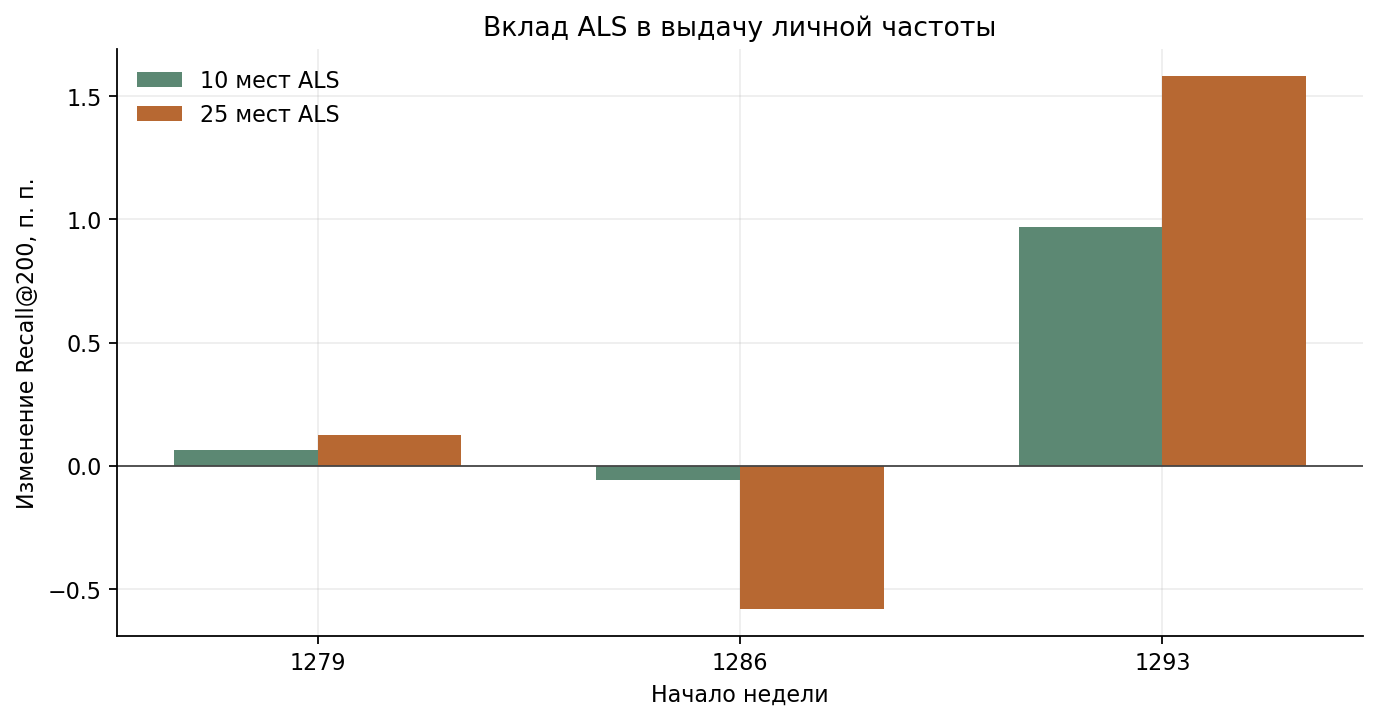

In [4]:
windows = read('temporal_als_20261104__window_summary.csv').set_index('anchor').sort_index()
q10 = read('temporal_als_20261104__quota10_sensitivity.csv')
mean_q10 = q10.groupby('anchor')['recall_reachable@200'].mean().reindex(windows.index)
assert mean_q10.notna().all()
delta_q10 = 100 * (mean_q10 - windows.personal_recall)
delta_q25 = 100 * (windows.fusion_mean - windows.personal_recall)
x = np.arange(len(windows))
width = 0.34
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.bar(x - width / 2, delta_q10, width, label='10 мест ALS', color='#5C8873')
ax.bar(x + width / 2, delta_q25, width, label='25 мест ALS', color='#B76832')
ax.axhline(0, color='#444444', linewidth=0.8)
ax.set(xticks=x, xticklabels=windows.index, xlabel='Начало недели',
       ylabel='Изменение Recall@200, п. п.', title='Вклад ALS в выдачу личной частоты')
ax.legend(frameon=False)
save_figure(fig, figures / 'quotas_by_window.png')
plt.show()

## Добавленные и потерянные попадания

Для каждого пользователя делим число добавленных и потерянных целей на исходное число его достижимых целей. Затем усредняем вклады по пользователям.

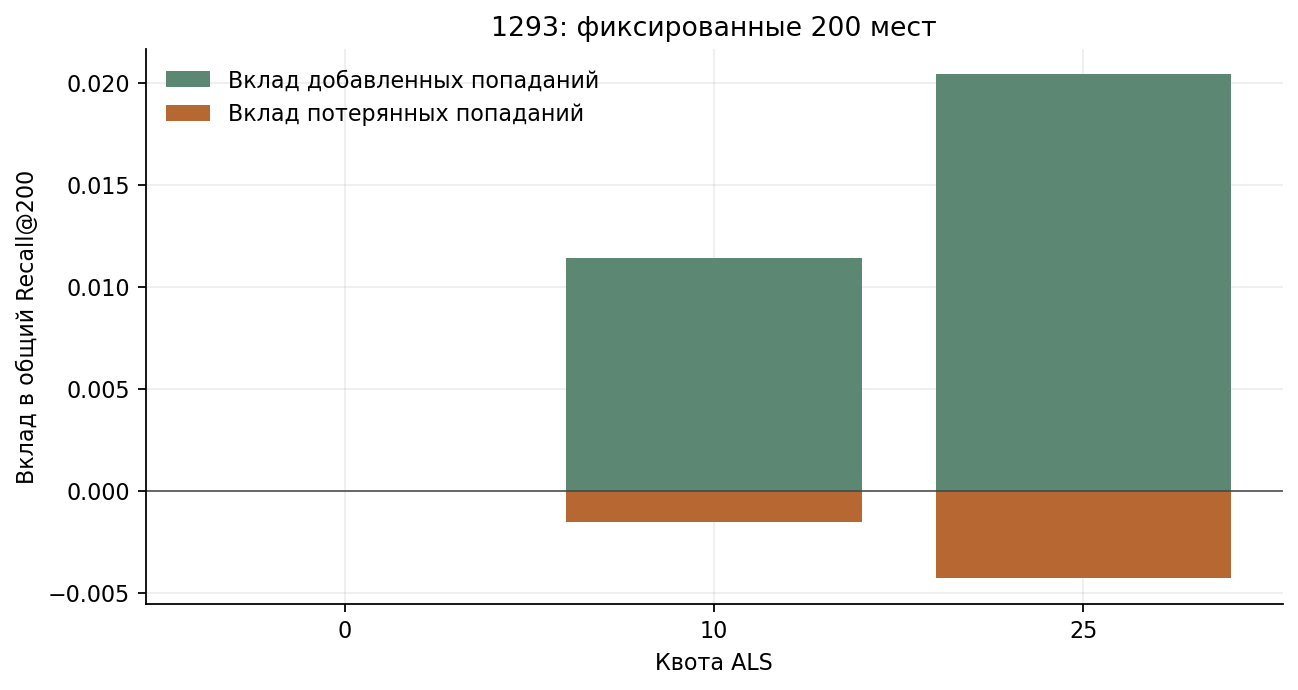

,quota_b,added_target_pairs,lost_target_pairs,difference,ci_low,ci_high
0,0,0,0,0.000000,0.000000,0.000000
1,10,143,24,0.009836,0.007648,0.012210
2,25,269,78,0.016133,0.013006,0.019112


In [5]:
channels = read('channel_contribution_20261104__comparison.csv')
fig, ax = plt.subplots(figsize=(8,4.2))
x=np.arange(len(channels))
ax.bar(x,channels.added_macro_mass,color='#5C8873',label='Вклад добавленных попаданий')
ax.bar(x,-channels.lost_macro_mass,color='#B76832',label='Вклад потерянных попаданий')
ax.axhline(0,color='#444444',linewidth=.7)
ax.set(xticks=x,xticklabels=channels.quota_b.astype(str),xlabel='Квота ALS',ylabel='Вклад в общий Recall@200',title='1293: фиксированные 200 мест')
ax.legend(frameon=False)
save_figure(fig, figures / 'added_lost.png')
plt.show()
assert np.allclose(channels.added_macro_mass-channels.lost_macro_mass,channels.difference)
display(channels[['quota_b','added_target_pairs','lost_target_pairs','difference','ci_low','ci_high']])

## Давность личной частоты

Полураспад 14 дней меняет порядок повторных товаров. В этих опытах набор первых 200 товаров и Recall@200 остались прежними.

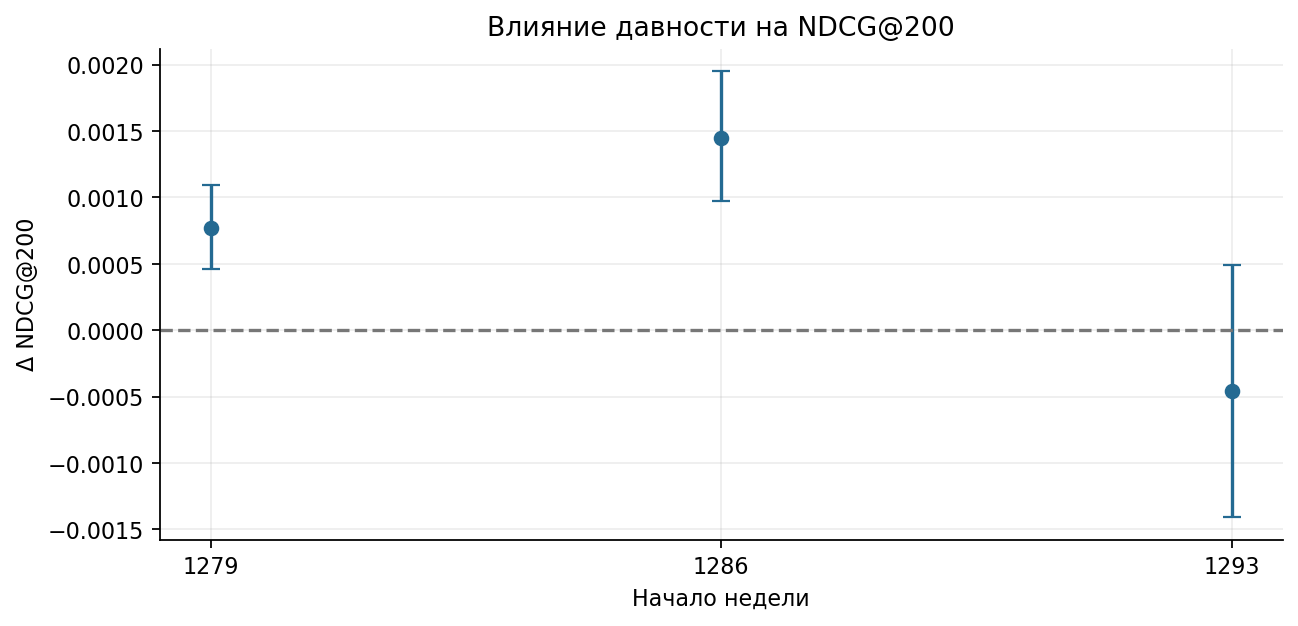

In [6]:
decay = read('focused_hypotheses_20261107__decay_summary.csv')
d=decay[decay.metric=='ndcg@200']
fig, ax = plt.subplots(figsize=(8,3.8))
ax.errorbar(d.anchor,d.delta,yerr=np.vstack([d.delta-d.low95,d.high95-d.delta]),fmt='o',capsize=4,color='#246A92')
ax.axhline(0,color='#777777',ls='--')
ax.set(xticks=d.anchor,xlabel='Начало недели',ylabel='Δ NDCG@200',title='Влияние давности на NDCG@200')
save_figure(fig, figures / 'decay_ndcg.png')
plt.show()

## Повторные и холодные товары

Повторный товар уже был в истории пользователя. Холодным здесь считаем товар, который не был целью в обучающих примерах.

In [7]:
display(read('repeat_cold_channels_20261105__repeat_summary.csv'))
display(read('repeat_cold_channels_20261105__cold_temporal__comparison.csv'))
display(read('multi_interest_20261105__comparison.csv'))

,variant,anchor,baseline,als,recency10,recency_matched,als_mean_slots,recency10_mean_slots,als_vs_age,interval_extremes
0,repeat,1279,0.191942,0.192344,0.193132,0.193058,9.251730,9.916158,-0.000713,"[-0.0016204976835537, 0.0001213565293163]"
1,repeat,1286,0.430761,0.428572,0.428138,0.428502,9.317360,9.956998,0.000069,"[-0.0013009902731291, 0.0014724979833011]"
2,repeat,1293,0.295046,0.306186,0.299248,0.298991,9.583852,9.982007,0.007194,"[0.0047166744833885, 0.0098958819503901]"
3,repeat_full_pool,1279,0.191942,0.192356,0.193132,0.193132,9.916158,9.916158,-0.000776,"[-0.0017119031781078, 6.7137602386497e-05]"
4,repeat_full_pool,1286,0.430761,0.428244,0.428138,0.428138,9.956998,9.956998,0.000106,"[-0.0012858019821015, 0.0015156940169616]"
5,repeat_full_pool,1293,0.295046,0.306381,0.299248,0.299248,9.982007,9.982007,0.007133,"[0.0046625015935259, 0.009740309535325]"


,n_targets,n_reachable,catalog_bound,recall_reachable@50,recall_all@50,hr@50,ndcg@50,recall_reachable@100,recall_all@100,hr@100,...,delta,low95,high95,paired_users,bootstrap_repetitions,mean_slots,changed_users,added_targets,lost_targets,final_test_used
0,3.570818,3.256919,0.927845,0.105800,0.100183,0.266284,0.042197,0.156005,0.147622,0.362499,...,-0.001475,-0.002077,-0.000935,9749,2000,9.950142,9779,13,51,False
1,3.570818,3.256919,0.927845,0.105800,0.100183,0.266284,0.042197,0.156005,0.147622,0.362499,...,-0.001553,-0.002143,-0.001014,9749,2000,9.950142,9779,6,51,False
2,3.570818,3.256919,0.927845,0.105800,0.100183,0.266284,0.042197,0.156005,0.147622,0.362499,...,-0.001449,-0.002053,-0.000906,9749,2000,9.950142,9779,11,51,False
3,3.570818,3.256919,0.927845,0.105800,0.100183,0.266284,0.042197,0.156005,0.147622,0.362499,...,-0.000861,-0.001526,-0.000196,9749,2000,9.950142,9779,30,51,False
4,3.670105,3.449381,0.953683,0.255393,0.245260,0.535521,0.092792,0.338755,0.325603,0.654030,...,-0.006510,-0.007854,-0.005224,6278,2000,9.939702,6264,3,149,False
5,3.670105,3.449381,0.953683,0.255393,0.245260,0.535521,0.092792,0.338755,0.325603,0.654030,...,-0.006459,-0.007797,-0.005181,6278,2000,9.939702,6264,3,149,False
6,3.670105,3.449381,0.953683,0.255393,0.245260,0.535521,0.092792,0.338755,0.325603,0.654030,...,-0.006535,-0.007868,-0.005279,6278,2000,9.939702,6264,4,149,False
7,3.670105,3.449381,0.953683,0.255393,0.245260,0.535521,0.092792,0.338755,0.325603,0.654030,...,-0.006217,-0.007581,-0.004929,6278,2000,9.939702,6264,5,149,False
8,3.948097,3.697347,0.953925,0.172785,0.166025,0.412827,0.087059,0.229188,0.220255,0.505210,...,-0.001807,-0.002698,-0.000946,4319,2000,9.868512,4278,5,33,False
9,3.948097,3.697347,0.953925,0.172785,0.166025,0.412827,0.087059,0.229188,0.220255,0.505210,...,-0.001774,-0.002700,-0.000900,4319,2000,9.868512,4278,5,33,False


,n_targets,n_reachable,catalog_bound,recall_reachable@50,recall_all@50,hr@50,ndcg@50,recall_reachable@100,recall_all@100,hr@100,...,hr@200,ndcg@200,users,users_with_targets,users_with_reachable,catalog_coverage@200,seed,method,own_minus_shuffled,final_test_used
0,3.948097,3.697347,0.953925,0.153044,0.146679,0.376013,0.073545,0.208342,0.199155,0.473489,...,0.587636,0.101215,4335,4335,4319,0.000421,2026,cluster2,0.009300,False
1,3.948097,3.697347,0.953925,0.174293,0.167469,0.415605,0.077810,0.226785,0.217954,0.502200,...,0.599676,0.104190,4335,4335,4319,0.016854,2026,cluster2_fusion10,NaN,False
2,3.948097,3.697347,0.953925,0.173923,0.167107,0.414679,0.078715,0.225607,0.216670,0.501273,...,0.625608,0.108446,4335,4335,4319,0.016840,2026,cluster2_fusion25,NaN,False
3,3.948097,3.697347,0.953925,0.153297,0.147010,0.375087,0.073644,0.209399,0.200022,0.473952,...,0.587868,0.101400,4335,4335,4319,0.000397,2026,random2,0.009180,False
4,3.948097,3.697347,0.953925,0.173980,0.167192,0.414911,0.077611,0.227145,0.218310,0.502663,...,0.598981,0.103991,4335,4335,4319,0.016854,2026,random2_fusion10,NaN,False
5,3.948097,3.697347,0.953925,0.173634,0.166859,0.414679,0.078527,0.225281,0.216347,0.500116,...,0.626534,0.108514,4335,4335,4319,0.016841,2026,random2_fusion25,NaN,False
6,3.948097,3.697347,0.953925,0.153382,0.147123,0.375318,0.073933,0.209390,0.199954,0.474647,...,0.589720,0.101709,4335,4335,4319,0.000386,2026,mean,0.011153,False
7,3.948097,3.697347,0.953925,0.173858,0.167078,0.414216,0.077704,0.227203,0.218362,0.502663,...,0.597592,0.103995,4335,4335,4319,0.016854,2026,mean_fusion10,NaN,False
8,3.948097,3.697347,0.953925,0.173518,0.166749,0.414216,0.078745,0.225705,0.216769,0.500810,...,0.627692,0.108869,4335,4335,4319,0.016841,2026,mean_fusion25,NaN,False
9,3.948097,3.697347,0.953925,0.147627,0.141465,0.366288,0.071568,0.202190,0.193076,0.465617,...,0.549896,0.095210,4335,4335,4319,0.000376,2027,cluster2,0.004253,False


## Неопределённость

Bootstrap оценивает разброс по пользователям, seed — разброс обучения. Итоги по периодам и выбор квоты приведены в README.